In [1]:
import matplotlib as plt
import matplotlib.pyplot as pyplt
import numpy as np
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

from slide_datatypes import difficulty_colours, SlidePattern, ChartDifficulty
from base_slide_dataset import full_df, pruned_df

In [2]:
len(pruned_df)

45151

In [3]:
pruned_df

,star_duration,slide_duration,slide_delay,cw_distance,pattern_group,bpm,difficulty,difficulty_constant,version,duration_ratio,duration_with_delay,duration_with_delay_ratio
0,0.352896,1.000,0.25,3,3,130.0,6,11.3,szt,0.352896,1.250,0.282317
1,0.352896,1.000,0.25,3,2,130.0,6,11.3,szt,0.352896,1.250,0.282317
4,0.125000,0.375,0.25,3,1,130.0,6,11.3,szt,0.333333,0.625,0.200000
6,0.115485,0.375,0.25,4,1,130.0,6,11.3,szt,0.307960,0.625,0.184776
13,0.125000,0.375,0.25,5,1,130.0,6,11.3,szt,0.333333,0.625,0.200000
...,...,...,...,...,...,...,...,...,...,...,...,...
119893,0.106800,0.375,0.25,4,5,215.0,5,13.2,sdt,0.284800,0.625,0.170880
119896,0.202700,0.625,0.25,6,12,215.0,5,13.2,sdt,0.324320,0.875,0.231657
119897,0.202700,0.625,0.25,1,11,215.0,5,13.2,sdt,0.324320,0.875,0.231657
119898,0.202700,0.625,0.25,1,12,215.0,5,13.2,sdt,0.324320,0.875,0.231657


In [4]:
master_df = pruned_df[pruned_df['difficulty'] == 5]
mas_outlier_removed_df = master_df[np.abs(stats.zscore(master_df['star_duration'])) < 3]
mas_straight_slide_df = mas_outlier_removed_df[mas_outlier_removed_df['pattern_group'] == SlidePattern.straight]
mas_across_straight_slide_df = mas_straight_slide_df[mas_straight_slide_df['cw_distance'] == 4]

remaster_df = pruned_df[pruned_df['difficulty'] == 6]
remas_outlier_removed_df = remaster_df[np.abs(stats.zscore(remaster_df['star_duration'])) < 3]
remas_straight_slide_df = remas_outlier_removed_df[remas_outlier_removed_df['pattern_group'] == SlidePattern.straight]
remas_across_straight_slide_df = remas_straight_slide_df[remas_straight_slide_df['cw_distance'] == 4]

mas_sdt_across_straight_slide_df = mas_across_straight_slide_df[mas_across_straight_slide_df['version'] == 'sdt']

len(mas_sdt_across_straight_slide_df)

510

In [5]:
mas_remas_df = pruned_df[(pruned_df['difficulty'] == 5) | (pruned_df['difficulty'] == 6)]
mas_remas_outlier_removed_df = mas_remas_df[(np.abs(stats.zscore(mas_remas_df['star_duration'])) < 3) & (np.abs(stats.zscore(mas_remas_df['slide_duration'])) < 3)]
mas_remas_straight_slide_df = mas_remas_outlier_removed_df[mas_remas_outlier_removed_df['pattern_group'] == SlidePattern.straight]
mas_remas_across_straight_slide_df = mas_remas_straight_slide_df[mas_remas_straight_slide_df['cw_distance'] == 4]
len(mas_remas_across_straight_slide_df)

1512

In [6]:
mas_constant_ten_above_df = mas_across_straight_slide_df[mas_across_straight_slide_df["difficulty_constant"] >= 10]
mas_sdt_constant_ten_above_df = mas_sdt_across_straight_slide_df[mas_sdt_across_straight_slide_df["difficulty_constant"] >= 10]

remas_constant_ten_above_df = remas_across_straight_slide_df[remas_across_straight_slide_df["difficulty_constant"] >= 10]

<Axes: xlabel='duration_with_delay', ylabel='star_duration'>

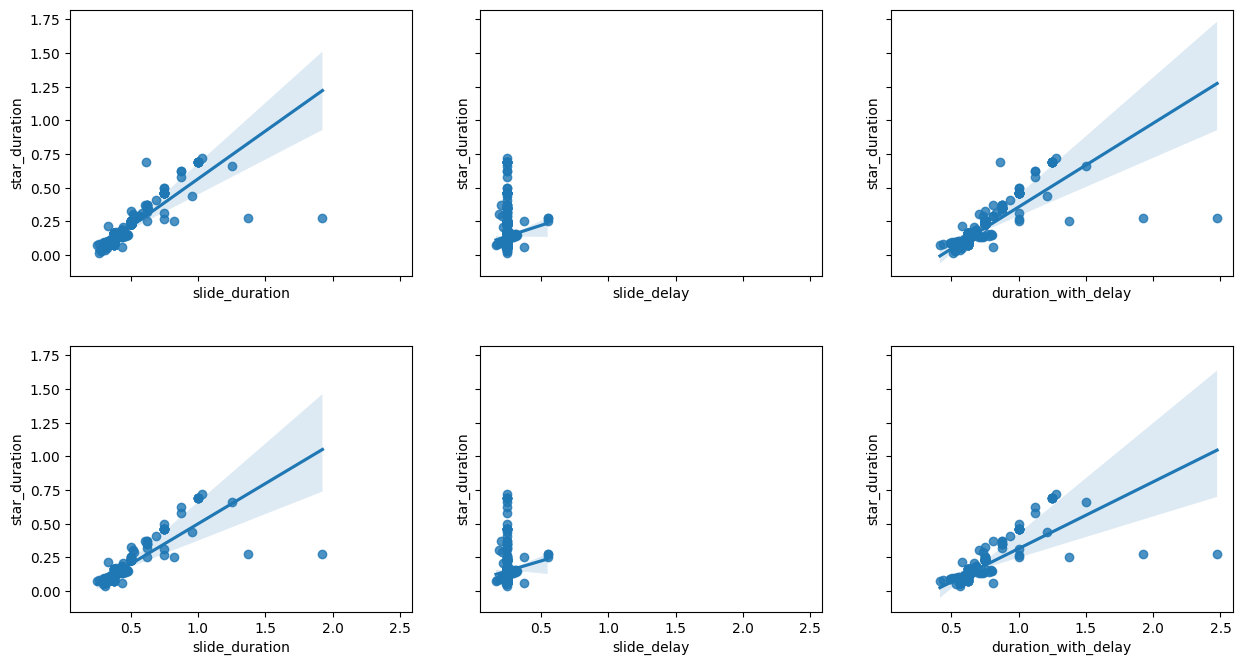

In [7]:
# star_duration_bpm_correlation_plot = sns.lmplot(data=outlier_removed_df, x="duration_with_delay", y="star_duration")
# star_duration_bpm_correlation_plot.figure.suptitle('Star duration vs BPM', x = 0.5, y = 1.1)
    # plot.text(10, 10, 'hello')

# plot.se(30, 30)

fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = pyplt.subplots(ncols=3, nrows=2, sharey=True, sharex=True, subplot_kw=dict(aspect='equal'), figsize=[15, 8])

sns.regplot(x=mas_across_straight_slide_df["slide_duration"], y=mas_across_straight_slide_df["star_duration"], ax=ax1)
sns.regplot(x=mas_across_straight_slide_df["slide_delay"], y=mas_across_straight_slide_df["star_duration"], ax=ax2)
sns.regplot(x=mas_across_straight_slide_df["duration_with_delay"], y=mas_across_straight_slide_df["star_duration"], ax=ax3)

sns.regplot(x=mas_sdt_across_straight_slide_df["slide_duration"], y=mas_sdt_across_straight_slide_df["star_duration"], ax=ax4)
sns.regplot(x=mas_sdt_across_straight_slide_df["slide_delay"], y=mas_sdt_across_straight_slide_df["star_duration"], ax=ax5)
sns.regplot(x=mas_sdt_across_straight_slide_df["duration_with_delay"], y=mas_sdt_across_straight_slide_df["star_duration"], ax=ax6)

# star_duration_bpm_correlation_plot.savefig(f"straight_slide_across_screen_outlier_chart.png")

<Axes: xlabel='duration_with_delay', ylabel='star_duration'>

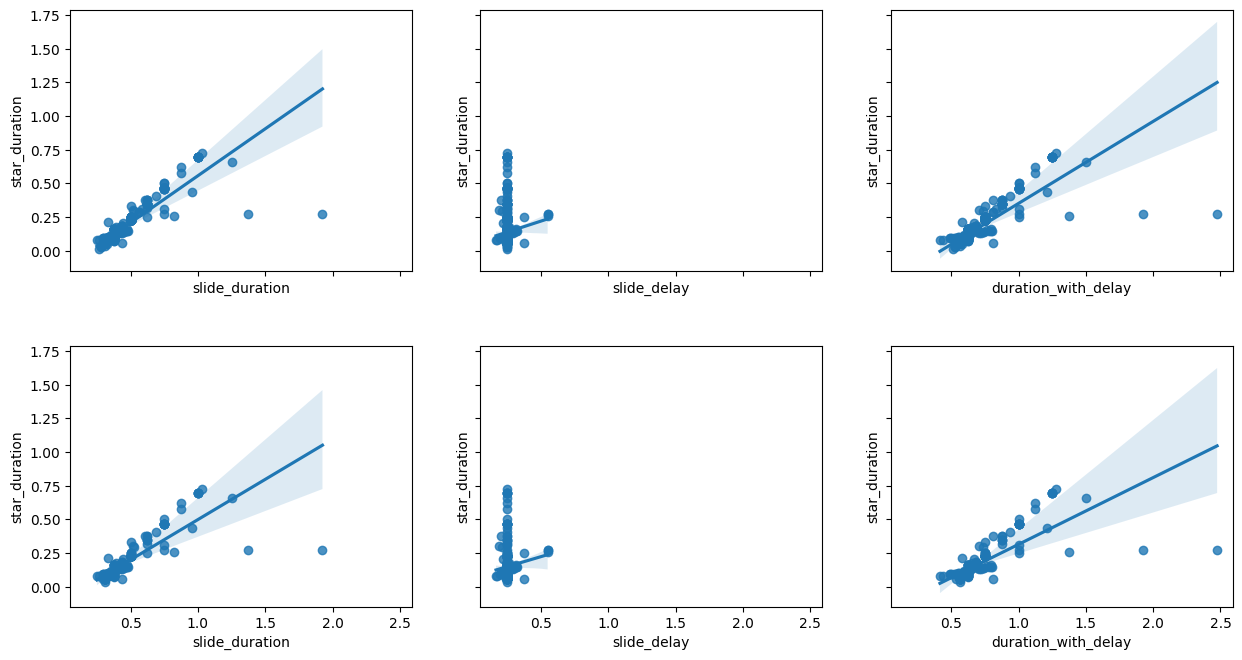

In [8]:
fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = pyplt.subplots(ncols=3, nrows=2, sharey=True, sharex=True, subplot_kw=dict(aspect='equal'), figsize=[15, 8])

sns.regplot(x=mas_constant_ten_above_df["slide_duration"], y=mas_constant_ten_above_df["star_duration"], ax=ax1)


sns.regplot(x=mas_constant_ten_above_df["slide_delay"], y=mas_constant_ten_above_df["star_duration"], ax=ax2)
sns.regplot(x=mas_constant_ten_above_df["duration_with_delay"], y=mas_constant_ten_above_df["star_duration"], ax=ax3)

sns.regplot(x=mas_sdt_constant_ten_above_df["slide_duration"], y=mas_sdt_constant_ten_above_df["star_duration"], ax=ax4)
sns.regplot(x=mas_sdt_constant_ten_above_df["slide_delay"], y=mas_sdt_constant_ten_above_df["star_duration"], ax=ax5)
sns.regplot(x=mas_sdt_constant_ten_above_df["duration_with_delay"], y=mas_sdt_constant_ten_above_df["star_duration"], ax=ax6)

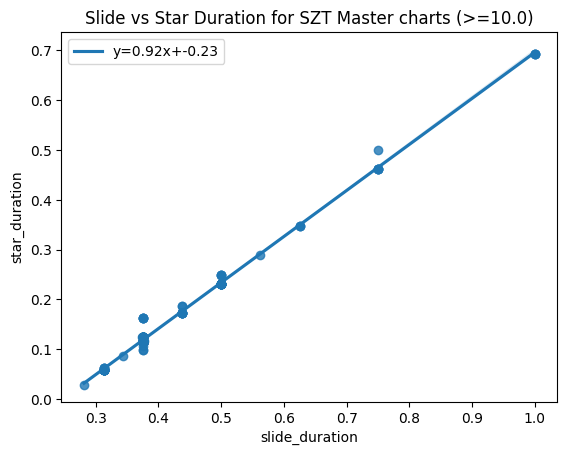

In [9]:
szt_constant_ten_above_df = mas_constant_ten_above_df[mas_constant_ten_above_df['version'] == 'szt']

# get coeffs of linear fit
result = stats.linregress(szt_constant_ten_above_df["slide_duration"], szt_constant_ten_above_df["star_duration"])


# use line_kws to set line label for legend
ax = sns.regplot(x="slide_duration", y="star_duration", data=szt_constant_ten_above_df, 
 line_kws={'label':"y={0:.2f}x+{1:.2f}".format(result.slope,result.intercept)})

ax.set_title("Slide vs Star Duration for SZT Master charts (>=10.0)")

# plot legend
ax.legend()

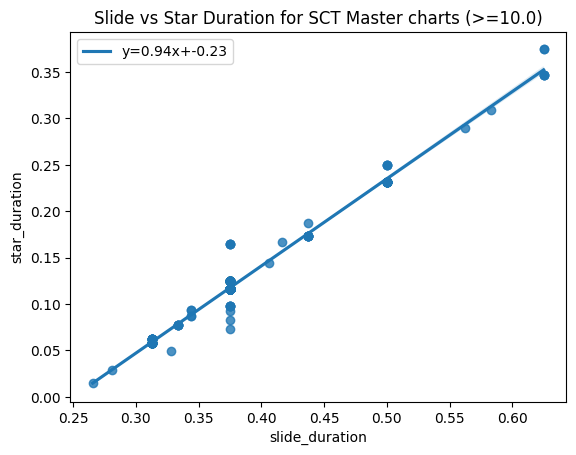

In [10]:
mas_sct_constant_ten_above_df = mas_constant_ten_above_df[mas_constant_ten_above_df['version'] == 'sct']

# get coeffs of linear fit
result = stats.linregress(mas_sct_constant_ten_above_df["slide_duration"], mas_sct_constant_ten_above_df["star_duration"])


# use line_kws to set line label for legend
ax = sns.regplot(x="slide_duration", y="star_duration", data=mas_sct_constant_ten_above_df, 
 line_kws={'label':"y={0:.2f}x+{1:.2f}".format(result.slope,result.intercept)})

ax.set_title("Slide vs Star Duration for SCT Master charts (>=10.0)")

# plot legend
ax.legend()

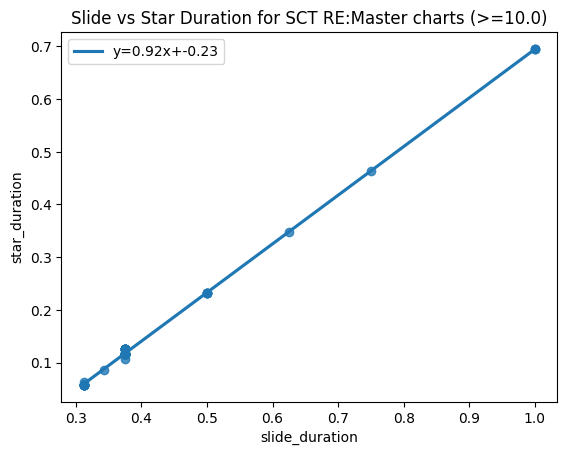

In [11]:
remas_sct_constant_ten_above_df = remas_constant_ten_above_df[remas_constant_ten_above_df['version'] == 'sct']

# get coeffs of linear fit
result = stats.linregress(remas_sct_constant_ten_above_df["slide_duration"], remas_sct_constant_ten_above_df["star_duration"])


# use line_kws to set line label for legend
ax = sns.regplot(x="slide_duration", y="star_duration", data=remas_sct_constant_ten_above_df, 
 line_kws={'label':"y={0:.2f}x+{1:.2f}".format(result.slope,result.intercept)})

ax.set_title("Slide vs Star Duration for SCT RE:Master charts (>=10.0)")

# plot legend
ax.legend()

In [12]:
remas_constant_ten_above_df = mas_constant_ten_above_df[mas_constant_ten_above_df['version'] == 'sct']

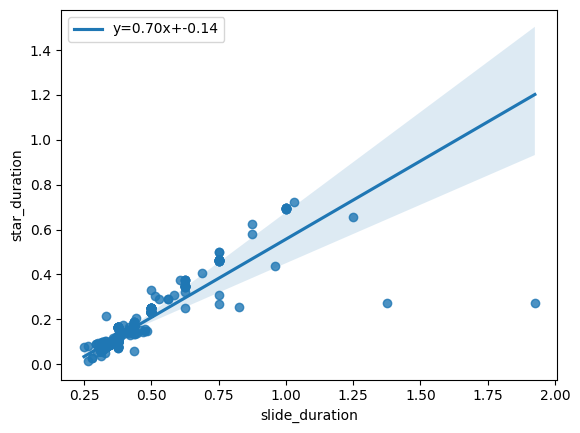

In [13]:
# get coeffs of linear fit
result = stats.linregress(mas_constant_ten_above_df["slide_duration"], mas_constant_ten_above_df["star_duration"])


# use line_kws to set line label for legend
ax = sns.regplot(x="slide_duration", y="star_duration", data=mas_constant_ten_above_df, 
 line_kws={'label':"y={0:.2f}x+{1:.2f}".format(result.slope,result.intercept)})

# plot legend
ax.legend()

Text(0.5, 1.0, 'Slide vs Star Duration across all Master Chart straight slides (>=10.0)')

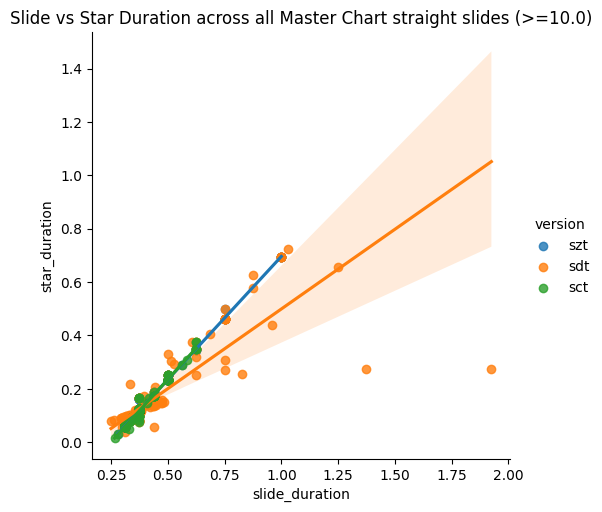

In [14]:
star_duration_bpm_correlation_plot = sns.lmplot(data=mas_constant_ten_above_df, x="slide_duration", y="star_duration", hue="version")
ax = pyplt.gca()
ax.set_title("Slide vs Star Duration across all Master Chart straight slides (>=10.0)")

c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\robust\robust_linear_model.py:289: ConvergenceWarning: Estimated scale is 0.0 indicating that the most last iteration produced a perfect fit of the weighted data.
  warnings.warn('Estimated scale is 0.0 indicating that the most'
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\robust\robust_linear_model.py:289: ConvergenceWarning: Estimated scale is 0.0 indicating that the most last iteration produced a perfect fit of the weighted data.
  warnings.warn('Estimated scale is 0.0 indicating that the most'
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\robust\robust_linear_model.py:289: ConvergenceWarning: Estimated scale is 0.0 indicating that the most last iteration produced a perfect fit of the weighted data.
  warnings.warn('Estimated scale is 0.0 indicating that the most'
c:\Users\Z

Text(0.5, 1.0, 'Slide vs Star Duration across all Master/RE:Master Chart straight slides')

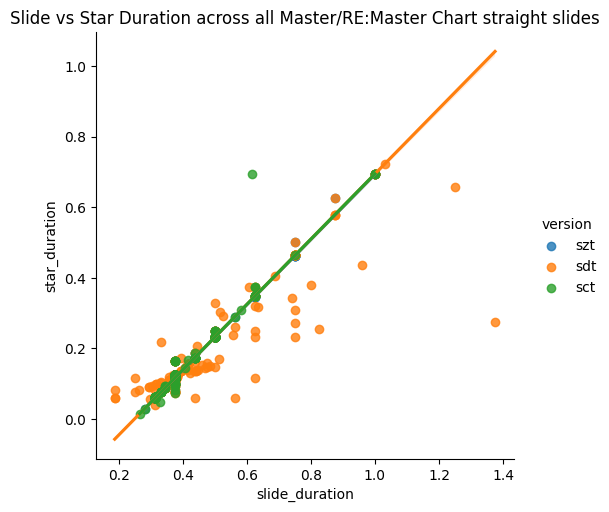

In [15]:
star_duration_bpm_correlation_plot = sns.lmplot(data=mas_remas_across_straight_slide_df, x="slide_duration", y="star_duration", hue="version", robust=True)
ax = pyplt.gca()
ax.set_title("Slide vs Star Duration across all Master/RE:Master Chart straight slides")

c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\robust\robust_linear_model.py:289: ConvergenceWarning: Estimated scale is 0.0 indicating that the most last iteration produced a perfect fit of the weighted data.
  warnings.warn('Estimated scale is 0.0 indicating that the most'
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\robust\robust_linear_model.py:289: ConvergenceWarning: Estimated scale is 0.0 indicating that the most last iteration produced a perfect fit of the weighted data.
  warnings.warn('Estimated scale is 0.0 indicating that the most'
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\robust\robust_linear_model.py:289: ConvergenceWarning: Estimated scale is 0.0 indicating that the most last iteration produced a perfect fit of the weighted data.
  warnings.warn('Estimated scale is 0.0 indicating that the most'
c:\Users\Z

Text(0.5, 1.0, 'Slide Duration + Delay vs Star Duration across all Master/RE:Master Chart straight slides')

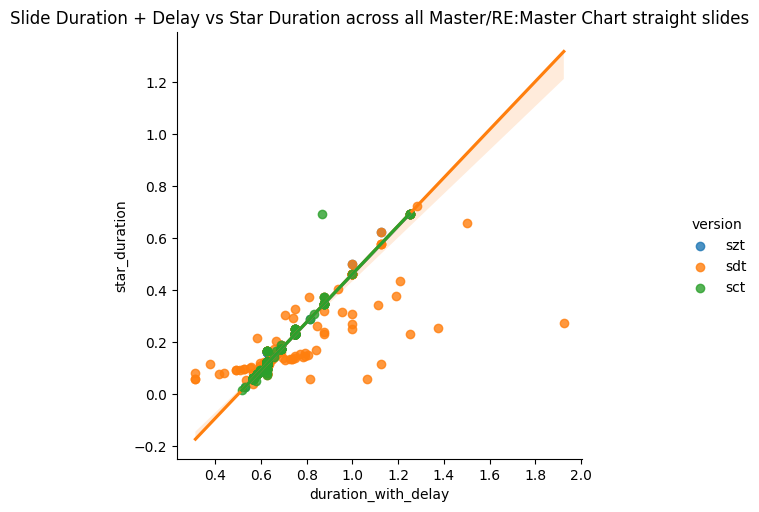

In [16]:
star_duration_bpm_correlation_plot = sns.lmplot(data=mas_remas_across_straight_slide_df, x="duration_with_delay", y="star_duration", hue="version", robust=True)
ax = pyplt.gca()
ax.set_title("Slide Duration + Delay vs Star Duration across all Master/RE:Master Chart straight slides")

In [17]:
# sdt_slides_by_chart = mas_sdt_across_straight_slide_df.groupby([''])
# result = stats.linregress(mas_remas_across_straight_slide_df["slide_duration"], mas_remas_across_straight_slide_df["star_duration"])

X = mas_remas_across_straight_slide_df[['slide_duration']]
y = mas_remas_across_straight_slide_df[['star_duration']]

# Add a constant column to the independent variables
X = sm.add_constant(X)

# Fit the multiple linear regression model
model = sm.RLM(y, X).fit()

# Print the summary of the model
print(model.summary())

# Print summary
# print(results.summary())

                    Robust linear Model Regression Results                    
Dep. Variable:          star_duration   No. Observations:                 1512
Model:                            RLM   Df Residuals:                     1510
Method:                          IRLS   Df Model:                            1
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Tue, 13 Oct 2026                                         
Time:                        23:22:22                                         
No. Iterations:                    50                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -0.2314   1.05e-05  -2.21e

In [ ]:
sdt_mas_remas_across_straight_slide_df = mas_remas_across_straight_slide_df[mas_remas_across_straight_slide_df['version'] == 'sdt']

X = sdt_mas_remas_across_straight_slide_df[['slide_duration']]
y = sdt_mas_remas_across_straight_slide_df[['star_duration']]

# Add a constant column to the independent variables
X = sm.add_constant(X)

# Fit the multiple linear regression model
model = sm.RLM(y, X).fit()

# Print the summary of the model
print(model.summary())


                    Robust linear Model Regression Results                    
Dep. Variable:          star_duration   No. Observations:                  631
Model:                            RLM   Df Residuals:                      629
Method:                          IRLS   Df Model:                            1
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Tue, 13 Oct 2026                                         
Time:                        23:22:22                                         
No. Iterations:                    50                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -0.2314   2.26e-05  -1.02e

In [26]:
print(model.params)
print(model.bse)
print(model.conf_int())

const            -0.231350
slide_duration    0.925669
dtype: float64
const             0.000023
slide_duration    0.000052
dtype: float64
                       0         1
const          -0.231395 -0.231306
slide_duration  0.925566  0.925771


## Check if Regression shows little/no deviation at different pattern distances

In [ ]:
star_duration_bpm_correlation_plot = sns.lmplot(data=mas_remas_straight_slide_df, x="duration_with_delay", y="star_duration", hue="cw_distance", robust=True)
ax = pyplt.gca()
ax.set_title("Slide Duration + Delay vs Star Duration across all Master/RE:Master Chart straight slides (separated by clockwise distance)")

In [44]:
import json

regressions_per_pattern_distance = {}

# TODO: Check details of model fields, calculate across all patterns/distances and save to JSON output
for pattern in SlidePattern:
    if pattern == SlidePattern.no_slide:
        continue
    
    regressions_per_pattern_distance[pattern.name] = {}
    
    slide_pattern_df = mas_remas_df[(mas_remas_df['pattern_group'] == pattern.value)]
    for cw_distance in range(1, 9):
        regressions_per_pattern_distance[pattern.name][cw_distance] = {}
        regression_data = regressions_per_pattern_distance[pattern.name][cw_distance]
        
        slide_pattern_with_distance_df = slide_pattern_df[slide_pattern_df['cw_distance'] == cw_distance]
        
        if len(slide_pattern_with_distance_df) < 2:
            continue
        
        X = slide_pattern_with_distance_df[['slide_duration']]
        y = slide_pattern_with_distance_df[['star_duration']]

        # Add a constant column to the independent variables
        X = sm.add_constant(X)

        # Fit the multiple linear regression model
        try:
            model = sm.RLM(y, X).fit()
        except Exception as e:
            print('fitting error with pattern', pattern.name, 'at distance', cw_distance)
        
        regression_data['population'] = model.nobs
        
        regression_data['slide_duration'] = {}
        regression_data['const'] = {}
        
        regression_data['slide_duration']['value'] = model.params['slide_duration']
        regression_data['const']['value'] = model.params['const']
        
        regression_data['slide_duration']['bse'] = model.bse['slide_duration']
        regression_data['const']['bse'] = model.bse['const']
        
        confidence_intervals = model.conf_int()
        regression_data['slide_duration']['interval'] = (confidence_intervals[0]['slide_duration'], confidence_intervals[1]['slide_duration'])
        regression_data['const']['interval'] = (confidence_intervals[0]['const'], confidence_intervals[1]['const'])

with open('slide_regressions_per_pattern_and_distance.json', 'w') as f:
    json.dump(regressions_per_pattern_distance, f, indent=4)



c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\regression\_tools.py:121: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid
c:\Users\Zestyy\OneDrive - MMU\Programming\Python\knowledge-base\.venv\Lib\site-packages\statsmodels\regression\_tools.py:121: RuntimeWarning: divide by zero encountered in scalar divide
  scale = np.dot(wresid, wresid) / df_resid


fitting error with pattern zigzag_s at distance 2
fitting error with pattern zigzag_z at distance 7


In [43]:
# TODO: Model at pattern level including all dis
regressions_per_pattern = {}

# TODO: Check details of model fields, calculate across all patterns/distances and save to JSON output
for pattern in SlidePattern:
    if pattern == SlidePattern.no_slide:
        continue
    
    regressions_per_pattern[pattern.name] = {}
    regression_data = regressions_per_pattern[pattern.name]
    
    slide_pattern_df = mas_remas_df[(mas_remas_df['pattern_group'] == pattern.value)]
    
    if len(slide_pattern_df) < 2:
        continue
    
    X = slide_pattern_df[['slide_duration']]
    y = slide_pattern_df[['star_duration']]

    # Add a constant column to the independent variables
    X = sm.add_constant(X)

    # Fit the multiple linear regression model
    try:
        model = sm.RLM(y, X).fit()
    except Exception as e:
        print('fitting error with pattern', pattern.name)
    
    regression_data['population'] = model.nobs
    
    regression_data['slide_duration'] = {}
    regression_data['const'] = {}
    
    regression_data['slide_duration']['value'] = model.params['slide_duration']
    regression_data['const']['value'] = model.params['const']
    
    regression_data['slide_duration']['bse'] = model.bse['slide_duration']
    regression_data['const']['bse'] = model.bse['const']
    
    confidence_intervals = model.conf_int()
    regression_data['slide_duration']['interval'] = (confidence_intervals[0]['slide_duration'], confidence_intervals[1]['slide_duration'])
    regression_data['const']['interval'] = (confidence_intervals[0]['const'], confidence_intervals[1]['const'])

with open('slide_regressions_per_pattern.json', 'w') as f:
    json.dump(regressions_per_pattern, f, indent=4)